# Proyecto Final: Finetuning de Stable Diffusion con LoRA sobre ilustraciones de libros antiguos

El objetivo es adaptar el modelo CompVis/stable-diffusion-v1-4 con LoRA para que genere imágenes con el estilo del dataset gigant/oldbookillustrations. Seguimos la misma metodología que en clase con Pokemon, adaptándola al nuevo dataset. Al final subimos la LoRA a Hugging Face y la volvemos a cargar desde allí para usarla.

Como el entrenamiento necesita GPU, he trabajado desde VS Code conectado a un servidor de Google Colab con una Tesla T4. Las dos primeras celdas comprueban que la GPU está disponible.

In [7]:
!nvidia-smi

Tue Oct 27 19:40:23 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   54C    P0             28W /   70W |    5449MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [8]:
import torch
print(torch.cuda.is_available())


True


# 0. Instalación de librerías

Instalamos las librerías de Hugging Face: diffusers para Stable Diffusion, transformers para CLIP, datasets para el dataset, peft para LoRA y accelerate para el entrenamiento en GPU. Desinstalamos torchao porque da conflictos con peft y no la necesitamos. Después importamos todo y definimos device para trabajar en la GPU.

In [9]:
!pip install -qq diffusers datasets accelerate peft

# Quitamos torchao porque da problemas con peft y no la usamos
!pip uninstall -qq -y torchao

In [10]:
# Importamos las librerias
from diffusers import StableDiffusionPipeline, DDPMScheduler
from diffusers import UNet2DConditionModel, AutoencoderKL, LMSDiscreteScheduler
from diffusers.utils import convert_state_dict_to_diffusers
from transformers import CLIPTextModel, CLIPTokenizer
from datasets import load_dataset
from accelerate import Accelerator
from peft import LoraConfig
from peft.utils import get_peft_model_state_dict
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
import os
from tqdm import tqdm

In [11]:
# Usamos la GPU si esta disponible

device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

cuda


# 1. Comportamiento original del modelo pre-entrenado

Antes de entrenar generamos una imagen con el modelo original. Nos sirve como referencia para comparar al final y ver qué ha aportado la LoRA.

### Cargar el modelo

StableDiffusionPipeline carga todas las piezas del modelo juntas y permite generar una imagen a partir de un texto con una sola llamada. Lo movemos a la GPU con .to(device).

In [12]:
pretrained_model_name = "CompVis/stable-diffusion-v1-4"

# Cargamos el modelo Stable Diffusion original
pipe = StableDiffusionPipeline.from_pretrained(
    pretrained_model_name,
).to(device)


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

### Generar la imagen previa (antes del finetuning)

El prompt va en inglés porque el text encoder (CLIP) y las descripciones del dataset están en inglés. Fijamos la semilla para que el ruido inicial sea siempre el mismo: así, con el mismo prompt, cualquier cambio en la imagen después del entrenamiento se deberá a la LoRA. Guardamos la imagen como antes_finetuning.png.

  0%|          | 0/50 [00:00<?, ?it/s]

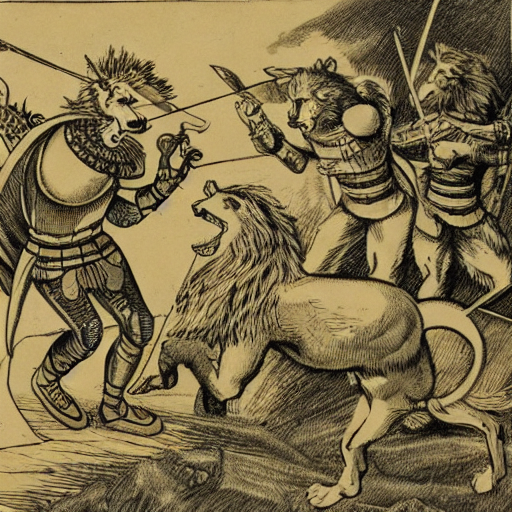

In [16]:
# Prompt que usaremos antes y despues de entrenar
prompt = "an old book illustration of a knight fighting with animals including a lion, a bear and a wolf."

# Fijamos la semilla para que salga siempre la misma imagen
seed = 42
generator = torch.Generator(device=device).manual_seed(seed)

image = pipe(prompt, generator=generator).images[0]

# Guardamos la imagen para compararla luego
image.save("antes_finetuning.png")

image


# 2. Cargamos el dataset para finetunear

Aquí es donde más cambia el código respecto a clase. El nuevo dataset tiene más columnas y sus imágenes no son cuadradas, así que hay que adaptar la carga y las transformaciones.

### Cargar el dataset, quedarnos con 2 columnas y tomar un subconjunto

Solo nos interesan las columnas 1600px (la imagen) e info_alt (su descripción), así que descartamos el resto. Quitamos las filas sin descripción, porque no aportan relación entre texto e imagen. Para que el entrenamiento no dure demasiado en Colab, usamos un subconjunto aleatorio de 800 imágenes. En la salida se ve que las imágenes tienen anchos distintos.

In [18]:
# Cargamos el dataset de ilustraciones antiguas
dataset_name = "gigant/oldbookillustrations"

dataset = load_dataset(dataset_name, split="train")

# Nos quedamos solo con la imagen y su descripcion
dataset = dataset.select_columns(["1600px", "info_alt"])

# Quitamos las imagenes que no tienen descripcion
dataset = dataset.filter(lambda x: x["info_alt"] is not None and len(x["info_alt"]) > 0)

# Cogemos 800 imagenes para que no tarde demasiado
num_samples = 800
dataset = dataset.shuffle(seed=42).select(range(num_samples))

# Vemos cuantas imagenes hay y algunos ejemplos
dataset_size = len(dataset)
print(f"Dataset con {dataset_size} imagenes")
for i in range(3):
    print(f"Imagen {i}: tamaño {dataset[i]['1600px'].size} | texto: {dataset[i]['info_alt']}")

README.md:   0%|          | 0.00/8.54k [00:00<?, ?B/s]

dataset_infos.json:   0%|          | 0.00/4.03k [00:00<?, ?B/s]

data/train-00000-of-00013-c0326990f575de(…): reconstructing file:   0%|          |  0.00B /  628MB            

data/train-00000-of-00013-c0326990f575de(…): downloading bytes:           |  0.00B            

data/train-00001-of-00013-a511e1086f1718(…): reconstructing file:   0%|          |  0.00B /  439MB            

...

data/train-00012-of-00013-cf490ec155e3b8(…): reconstructing file:   0%|          |  0.00B /  388MB            

data/train-00012-of-00013-cf490ec155e3b8(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/4154 [00:00<?, ? examples/s]

Filter:   0%|          | 0/4154 [00:00<?, ? examples/s]

Dataset con 800 imagenes
Imagen 0: tamaño (1121, 1600) | texto: They were changed into swans
Imagen 1: tamaño (1242, 1600) | texto: Balochard
Imagen 2: tamaño (1213, 1600) | texto: A group of men entering a palace are invited by their hostess to look at a piece of tapestry


### Transformaciones de las imágenes

El modelo trabaja a 512×512, pero estas imágenes no son cuadradas y Resize((512, 512)) las deformaría. Por eso usamos Resize(512), que escala manteniendo la proporción, y después CenterCrop(512), que recorta el centro. Por último las convertimos a tensor y las normalizamos al rango [-1, 1].

In [19]:
# Transformaciones para dejar las imagenes en 512x512
resolution = 512
image_transforms = transforms.Compose([
    # Las imagenes no son cuadradas, asi que primero escalamos sin deformar
    transforms.Resize(resolution),
    # y despues recortamos el centro
    transforms.CenterCrop(resolution),
    transforms.ToTensor(),                                   # convertir a tensor
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]),  # normalizacion
])

### Comprobación visual: imagen original frente a transformada

Aplicamos las transformaciones a una imagen para comprobar que queda en 512×512 sin deformarse. Usamos .convert("RGB") porque algunas ilustraciones están en escala de grises, y deshacemos la normalización solo para poder visualizarla bien.

Original: (1121, 1600) -> Transformada: (512, 512)


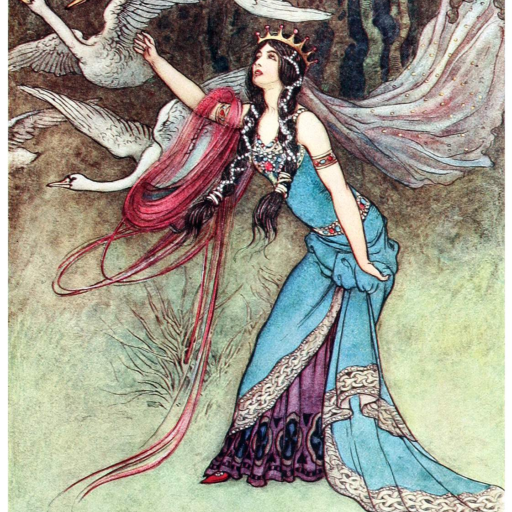

In [20]:
# Probamos las transformaciones con una imagen
original_image = dataset[0]["1600px"].convert("RGB")
transformed_image = image_transforms(original_image)
transformed_pil_image = transforms.ToPILImage()(transformed_image * 0.5 + 0.5)  # para verla bien

print(f"Original: {original_image.size} -> Transformada: {transformed_pil_image.size}")
transformed_pil_image


### Dataset wrapper y DataLoader

La clase Text2ImageDataset prepara cada ejemplo para el entrenamiento: transforma la imagen y tokeniza su descripción con el tokenizador de CLIP. Respecto a clase, solo cambian los nombres de las columnas. El DataLoader agrupa los ejemplos en batches de 3, que es lo que cabe en la memoria de la GPU.

In [21]:
# Preparamos el dataset para el entrenamiento
batch_size = 3  # mas no cabe en la GPU

class Text2ImageDataset(Dataset):
    def __init__(self, dataset):
        self.dataset = dataset

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        example = self.dataset[idx]
        # Aqui cambian los nombres de las columnas respecto a clase
        image = image_transforms(example["1600px"].convert("RGB"))
        token = tokenizer(example["info_alt"], padding="max_length", truncation=True, max_length=tokenizer.model_max_length, return_tensors="pt")
        return {
            "pixel_values": image,
            "input_ids": token.input_ids.squeeze(0),
            "attention_mask": token.attention_mask.squeeze(0),
        }

train_dataset = Text2ImageDataset(dataset)
train_dataloader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

# 3. Cargamos las componentes del modelo por separado

Para entrenar necesitamos acceder a cada pieza de Stable Diffusion por separado, porque cada una se usa en un paso distinto del entrenamiento y solo vamos a modificar la UNet.

### Liberar la GPU

Borramos el pipeline de la sección 1 y vaciamos la caché de la GPU. Así dejamos memoria libre para cargar las piezas por separado y para el entrenamiento.

In [22]:
# Borramos el pipeline para liberar memoria de la GPU
del pipe
torch.cuda.empty_cache()


### Cargar las componentes

El tokenizer y el text encoder (CLIP) convierten el texto en vectores. El scheduler define cómo se añade ruido según el timestep. El VAE pasa las imágenes al espacio latente y viceversa, y la UNet es la que predice el ruido: es la pieza a la que añadiremos la LoRA.

In [23]:
# Tokenizador:
tokenizer = CLIPTokenizer.from_pretrained(pretrained_model_name, subfolder='tokenizer')

# Scheduler:
noise_scheduler = DDPMScheduler.from_pretrained(pretrained_model_name, subfolder="scheduler")

# Text Encoder:
text_encoder = CLIPTextModel.from_pretrained(
    pretrained_model_name,
    subfolder="text_encoder",
).to(device)

# VAE:
vae = AutoencoderKL.from_pretrained(
    pretrained_model_name,
    subfolder="vae",
).to(device)

# La UNet:
unet = UNet2DConditionModel.from_pretrained(
    pretrained_model_name,
    subfolder="unet",
).to(device)


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

### Congelar el VAE y el text encoder

El VAE y el text encoder no se entrenan, porque ya hacen bien su trabajo. Los ponemos en modo evaluación y desactivamos sus gradientes, lo que también ahorra memoria. Los pesos originales de la UNet los congela peft automáticamente al añadir la LoRA.

In [24]:
# El VAE y el text encoder no se entrenan
vae.eval()
text_encoder.eval()

for param in vae.parameters():
    param.requires_grad = False
for param in text_encoder.parameters():
    param.requires_grad = False


# 4. Añadimos la LoRA y preparamos el entrenamiento

En lugar de entrenar toda la UNet, LoRA congela sus pesos y añade a las capas de atención dos matrices pequeñas de rango r, que son lo único que se entrena. Así se entrena menos del 1 % de los parámetros, como se ve en la salida, con mucha menos memoria. El optimizador se crea solo con los parámetros de la LoRA, y Accelerator lo prepara todo para la GPU.

In [25]:
# Parametros de la LoRA
lora_rank = 6     # tamaño de la LoRA
lora_alpha = 6    # normalmente igual que el rank

# Añadimos la LoRA a la UNet
lora_config = LoraConfig(
    r=lora_rank,
    lora_alpha=lora_alpha,
    init_lora_weights="gaussian",
    target_modules=["to_k", "to_q", "to_v", "to_out.0"],
)
unet.add_adapter(lora_config, adapter_name="oldbook")

# Vemos cuantos parametros se entrenan
lora_params = [p for p in unet.parameters() if p.requires_grad]
n_lora = sum(p.numel() for p in lora_params)
n_total = sum(p.numel() for p in unet.parameters())
print(f"Parametros entrenables (LoRA): {n_lora:,} de {n_total:,} ({100 * n_lora / n_total:.2f}%)")

# El optimizador solo actualiza la LoRA
learning_rate = 1e-4
optimizer = torch.optim.AdamW(lora_params, lr=learning_rate)

# Preparamos todo para la GPU
accelerator = Accelerator()
unet, optimizer, train_dataloader = accelerator.prepare(unet, optimizer, train_dataloader)
print(accelerator.device)


Parametros entrenables (LoRA): 1,195,776 de 860,716,740 (0.14%)
cuda


# 5. Proceso de entrenamiento: finetuning con LoRA

El bucle es el mismo que en un finetuning completo. La diferencia es que el optimizador solo actualiza los pesos de la LoRA.

### El bucle de entrenamiento

Para cada batch, el VAE pasa las imágenes al espacio latente y les añadimos ruido en un timestep aleatorio. La UNet, con la LoRA y guiada por el texto, intenta predecir ese ruido. El error entre el ruido real y el predicho (MSE) se usa para actualizar solo los pesos de la LoRA. Además, guardamos la loss media de cada época para analizarla después.

In [26]:
# Entrenamiento
num_epochs = 5
epoch_losses = []  # para guardar la loss de cada epoca

unet.train()
for epoch in range(num_epochs):
    progress_bar = tqdm(train_dataloader, desc=f"Epoch {epoch}")
    running_loss = 0.0

    for batch in progress_bar:

        # Pasamos las imagenes al espacio latente con el VAE
        with torch.no_grad():
            latents = vae.encode(batch["pixel_values"].to(accelerator.device)).latent_dist.sample()
            latents = latents * 0.18215

        # Añadimos ruido:
        # 1. Ruido aleatorio
        noise = torch.randn_like(latents)
        # 2. Timestep aleatorio
        timesteps = torch.randint(0, noise_scheduler.config.num_train_timesteps, (latents.shape[0],), device=latents.device).long()
        # 3. Mezclamos la imagen con el ruido
        noisy_latents = noise_scheduler.add_noise(latents, noise, timesteps)

        # Pasamos el texto a vectores
        encoder_hidden_states = text_encoder(batch["input_ids"].to(accelerator.device))[0]

        # La UNet intenta adivinar el ruido
        noise_pred = unet(noisy_latents, timesteps, encoder_hidden_states).sample

        # Calculamos el error y actualizamos la LoRA
        loss = torch.nn.functional.mse_loss(noise_pred, noise)
        accelerator.backward(loss)
        optimizer.step()
        optimizer.zero_grad()

        running_loss += loss.item()
        progress_bar.set_postfix(loss=loss.item())

    epoch_losses.append(running_loss / len(train_dataloader))
    print(f"Epoch {epoch}: loss media = {epoch_losses[-1]:.4f}")


Epoch 0: 100%|██████████| 267/267 [18:23<00:00,  4.13s/it, loss=0.0464] 


Epoch 0: loss media = 0.1449


Epoch 1: 100%|██████████| 267/267 [18:21<00:00,  4.12s/it, loss=0.51]   


Epoch 1: loss media = 0.1503


Epoch 2: 100%|██████████| 267/267 [18:20<00:00,  4.12s/it, loss=0.0503] 


Epoch 2: loss media = 0.1382


Epoch 3: 100%|██████████| 267/267 [18:20<00:00,  4.12s/it, loss=0.0259] 


Epoch 3: loss media = 0.1518


Epoch 4: 100%|██████████| 267/267 [18:20<00:00,  4.12s/it, loss=0.105]  

Epoch 4: loss media = 0.1470


### Gráfica de la loss

La loss media se mantiene casi plana entre épocas, y es normal en modelos de difusión. Depende mucho del timestep aleatorio de cada batch, y el modelo base ya predecía bien el ruido desde el principio. La LoRA cambia sobre todo el estilo de las imágenes, así que la mejor forma de evaluarla es mirar los resultados.

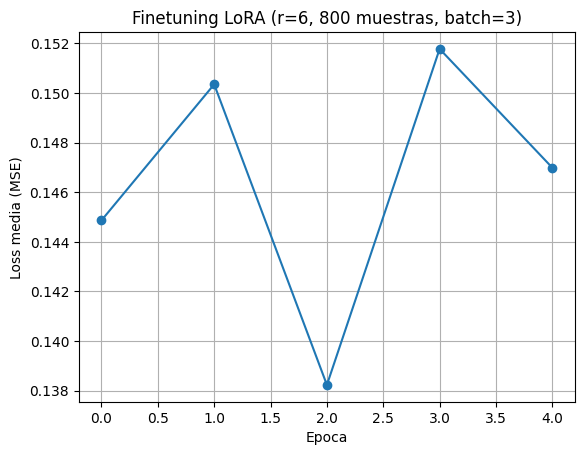

In [27]:
# Grafica de la loss por epoca
import matplotlib.pyplot as plt

plt.plot(range(len(epoch_losses)), epoch_losses, marker="o")
plt.xlabel("Epoca")
plt.ylabel("Loss media (MSE)")
plt.title(f"Finetuning LoRA (r={lora_rank}, {num_samples} muestras, batch={batch_size})")
plt.grid(True)
plt.show()


# 6. Generamos imágenes con la LoRA entrenada

Volvemos a generar con el mismo prompt y la misma semilla que en la sección 1, ahora con la LoRA entrenada, para comparar el antes y el después.

### Montar el pipeline con la UNet entrenada

Liberamos el optimizador, que ya no hace falta, y recuperamos la UNet entrenada con unwrap_model. Montamos el pipeline reutilizando las piezas que ya están en memoria, con nuestra UNet en lugar de la original. Con set_adapters activamos la LoRA con intensidad 1.

In [28]:
# El optimizador ya no hace falta
del optimizer
torch.cuda.empty_cache()

# Cogemos la UNet ya entrenada
unet = accelerator.unwrap_model(unet)
unet.eval()

# Montamos el pipeline con nuestra UNet
pipe = StableDiffusionPipeline.from_pretrained(
    pretrained_model_name,
    unet=unet,
    vae=vae,
    text_encoder=text_encoder,
    tokenizer=tokenizer,
).to(device)

# Activamos la LoRA al 100%
pipe.set_adapters(["oldbook"], adapter_weights=[1.0])

print('Pipeline con LoRA listo!')


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Pipeline con LoRA listo!


### Generar la imagen "después"

Usamos la misma variable prompt y la misma semilla que antes, así que la única diferencia es la LoRA. Guardamos la imagen como despues_finetuning.png.

an old book illustration of a knight fighting with animals including a lion, a bear and a wolf.


  0%|          | 0/50 [00:00<?, ?it/s]

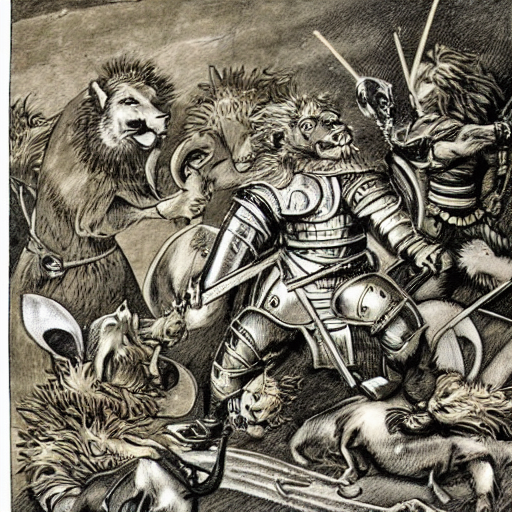

In [29]:
# Mismo prompt y misma semilla que antes
print(prompt)
seed = 42
generator = torch.Generator(device=device).manual_seed(seed)

image = pipe(prompt, generator=generator).images[0]

# Guardamos la imagen de despues
image.save("despues_finetuning.png")

image


### Comparativa antes / después

Ponemos las dos imágenes juntas y lo guardamos como comparativa.png. La imagen original tiene tonos sepia y un trazo más simple. Con la LoRA aparecen tonos grises y el rayado típico de los grabados antiguos. La escena se parece porque el prompt y la semilla son los mismos, pero el estilo ha cambiado hacia el del dataset.

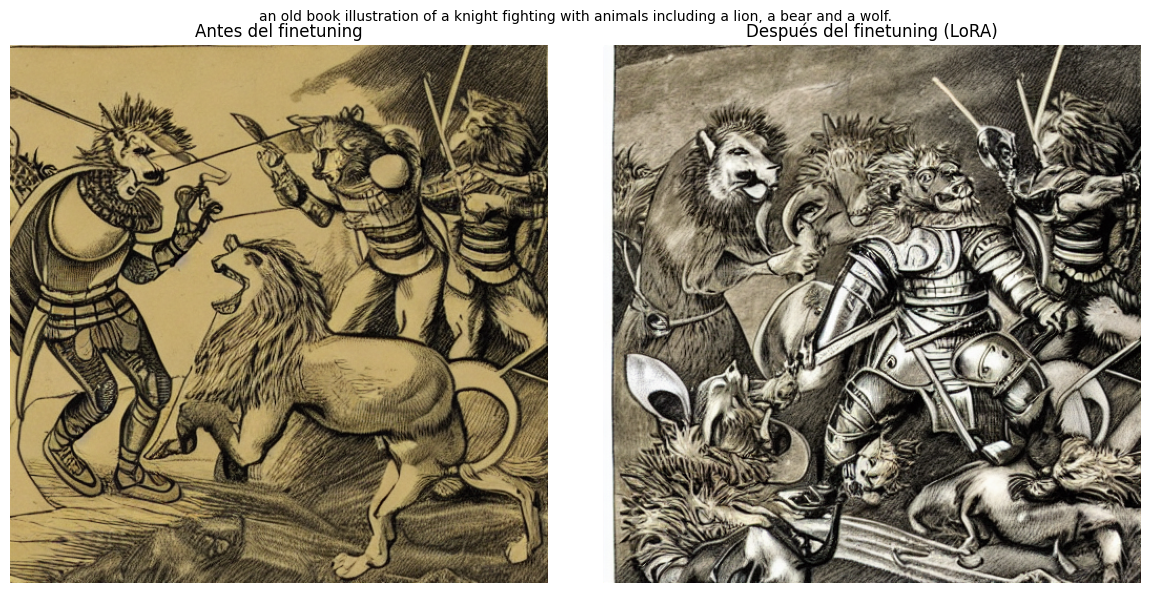

In [30]:
# Ponemos las dos imagenes juntas
antes = Image.open("antes_finetuning.png")
despues = Image.open("despues_finetuning.png")

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(antes);   axes[0].set_title("Antes del finetuning");   axes[0].axis("off")
axes[1].imshow(despues); axes[1].set_title("Después del finetuning (LoRA)"); axes[1].axis("off")
fig.suptitle(prompt, fontsize=10)
plt.tight_layout()
plt.savefig("comparativa.png", dpi=100)
plt.show()


# 7. Guardamos la LoRA y la subimos a Hugging Face

La LoRA entrenada solo existe en la memoria del servidor, y si se desconecta se pierde. En esta sección la guardamos y la subimos a un repositorio de mi perfil de Hugging Face.

### Login en Hugging Face

Para subir archivos hace falta un token de tipo Write. Lo pedimos con getpass para que no quede escrito en el notebook, ya que el token funciona como una contraseña. whoami() comprueba con qué usuario hemos iniciado sesión.

In [34]:
# Login en Hugging Face (el token se pega en el cuadro, no en el codigo)
from huggingface_hub import login, whoami
from getpass import getpass

login(token=getpass("Pega tu token de Hugging Face (Write): ").strip())

# Comprobamos el usuario
hf_username = whoami()["name"]
print(f"Sesion iniciada como: {hf_username}")


Sesion iniciada como: estaluis


### Guardar los pesos de la LoRA

Extraemos solo los pesos de la LoRA y los convertimos al formato de diffusers para poder cargarlos después con load_lora_weights. Se guardan en un archivo .safetensors de pocos MB, porque el modelo base no se incluye. También copiamos las imágenes de ejemplo para subirlas junto al modelo.

In [35]:
# Sacamos solo los pesos de la LoRA
unet_lora_state_dict = convert_state_dict_to_diffusers(
    get_peft_model_state_dict(unet, adapter_name="oldbook")
)

# Los guardamos en una carpeta
lora_dir = "sd-v1-4-oldbookillustrations-lora"
StableDiffusionPipeline.save_lora_weights(
    save_directory=lora_dir,
    unet_lora_layers=unet_lora_state_dict,
    safe_serialization=True,
)

# Copiamos tambien las imagenes para subirlas
import shutil
for f in ["antes_finetuning.png", "despues_finetuning.png", "comparativa.png"]:
    shutil.copy(f, lora_dir)

print(os.listdir(lora_dir))


['antes_finetuning.png', 'despues_finetuning.png', 'comparativa.png', 'pytorch_lora_weights.safetensors']


### Model card (README del repositorio)

La model card es el README del repositorio en Hugging Face. Indica el modelo base, el dataset, los hiperparámetros y cómo usar la LoRA, e incluye la comparativa. Los valores se rellenan automáticamente con las variables del notebook.

In [37]:
# README del repositorio en Hugging Face
model_card = f"""---
base_model: {pretrained_model_name}
datasets:
- gigant/oldbookillustrations
library_name: diffusers
tags:
- stable-diffusion
- lora
- text-to-image
---

# Stable Diffusion v1-4 + LoRA: ilustraciones de libros antiguos

LoRA entrenada sobre `{pretrained_model_name}` con {num_samples} imágenes del dataset
`gigant/oldbookillustrations` (columnas `1600px` e `info_alt`).

## Hiperparámetros
- LoRA rank (r): {lora_rank} | alpha: {lora_alpha}
- Épocas: {num_epochs} | batch size: {batch_size} | learning rate: {learning_rate}
- Resolución: {resolution} (Resize + CenterCrop)

## Uso
~~~python
from diffusers import StableDiffusionPipeline
pipe = StableDiffusionPipeline.from_pretrained("{pretrained_model_name}").to("cuda")
pipe.load_lora_weights("{hf_username}/{lora_dir}")
image = pipe("{prompt}").images[0]
~~~

## Antes / después (mismo prompt y semilla)
![comparativa](comparativa.png)
"""

with open(os.path.join(lora_dir, "README.md"), "w", encoding="utf-8") as f:
    f.write(model_card)

print(model_card)


---
base_model: CompVis/stable-diffusion-v1-4
datasets:
- gigant/oldbookillustrations
library_name: diffusers
tags:
- stable-diffusion
- lora
- text-to-image
---

# Stable Diffusion v1-4 + LoRA: ilustraciones de libros antiguos

LoRA entrenada sobre `CompVis/stable-diffusion-v1-4` con 800 imágenes del dataset
`gigant/oldbookillustrations` (columnas `1600px` e `info_alt`).

## Hiperparámetros
- LoRA rank (r): 6 | alpha: 6
- Épocas: 5 | batch size: 3 | learning rate: 0.0001
- Resolución: 512 (Resize + CenterCrop)

## Uso
~~~python
from diffusers import StableDiffusionPipeline
pipe = StableDiffusionPipeline.from_pretrained("CompVis/stable-diffusion-v1-4").to("cuda")
pipe.load_lora_weights("estaluis/sd-v1-4-oldbookillustrations-lora")
image = pipe("an old book illustration of a knight fighting with animals including a lion, a bear and a wolf.").images[0]
~~~

## Antes / después (mismo prompt y semilla)
![comparativa](comparativa.png)



### Crear el repositorio y subir la LoRA

Creamos el repositorio en mi perfil y subimos la carpeta completa: los pesos, la model card y las imágenes. El modelo queda publicado en https://huggingface.co/estaluis/sd-v1-4-oldbookillustrations-lora

In [39]:
# Creamos el repositorio y subimos la carpeta
from huggingface_hub import create_repo, upload_folder

repo_id = f"{hf_username}/{lora_dir}"
create_repo(repo_id, exist_ok=True)
upload_folder(repo_id=repo_id, folder_path=lora_dir)

print(f"Modelo subido: https://huggingface.co/{repo_id}")


Modelo subido: https://huggingface.co/estaluis/sd-v1-4-oldbookillustrations-lora


# 8. Cargamos el modelo finetuneado desde Hugging Face y lo usamos

Para comprobar que el modelo subido funciona, lo cargamos desde Hugging Face como lo haría cualquier otro usuario. Primero liberamos la GPU borrando el pipeline y las piezas del entrenamiento. Así nos aseguramos de que se usa la LoRA descargada y no la que seguía en memoria.

In [40]:
# Borramos todo de memoria para empezar de cero
for nombre in ["pipe", "unet", "vae", "text_encoder"]:
    globals().pop(nombre, None)
torch.cuda.empty_cache()


### Cargar el modelo base y la LoRA desde el Hub

Cargamos el modelo original de CompVis y, encima, nuestra LoRA con load_lora_weights, que la descarga directamente de mi repositorio.

In [ ]:
# Cargamos el modelo original
pipe = StableDiffusionPipeline.from_pretrained(pretrained_model_name).to(device)

# y le añadimos nuestra LoRA desde Hugging Face
pipe.load_lora_weights(repo_id, adapter_name="oldbook")
print(f"LoRA cargada desde https://huggingface.co/{repo_id}")

### Generar con el modelo descargado

Generamos con el mismo prompt y la misma semilla. Si todo se ha subido bien, la imagen debe ser prácticamente igual a despues_finetuning.png, lo que demuestra que el modelo publicado funciona.

In [ ]:
# Generamos con el mismo prompt y semilla
generator = torch.Generator(device=device).manual_seed(seed)
image = pipe(prompt, generator=generator).images[0]
image.save("despues_desde_hf.png")
image